Q.1 Equilibrium conversion checker 

In a reactor, the reaction A + B = C reaches equilibrium.

Initial concentrations are [A] = 1.5, [B] = 1.0, and [C] = 0 mol/L. If x mol/L of C is formed, then:

`Kc = x / ((1.5 - x)(1 - x))`

This rearranges to the quadratic equation:

`Kc*x^2 - (2.5*Kc + 1)*x + 1.5*Kc = 0`

**a)** Read `Kc` using `input()`, print the data types of the raw input and converted value, and show a clear message if `Kc <= 0`.

In [19]:
raw_kc = input("Enter Kc: ")
print("Raw input type:", type(raw_kc))
kc = None

try:
    kc = float(raw_kc)
    print("Converted value type:", type(kc))
    if kc <= 0:
        print("Kc must be greater than 0.")
except ValueError:
    print("Please enter a valid numeric value for Kc.")

Raw input type: <class 'str'>
Converted value type: <class 'float'>


b)finds a,b,c,the discriminant and both roots;

In [20]:
import math

if kc is None:
    print("Cannot calculate the roots: enter a valid numeric Kc in part a.")
elif kc <= 0:
    print("Cannot calculate the roots: Kc must be greater than 0.")
else:
    a = kc
    b = -(2.5 * kc + 1)
    c = 1.5 * kc
    discriminant = b**2 - 4 * a * c

    print("a =", a)
    print("b =", b)
    print("c =", c)
    print("Discriminant =", discriminant)

    if discriminant >= 0:
        sqrt_discriminant = math.sqrt(discriminant)
        root1 = (-b + sqrt_discriminant) / (2 * a)
        root2 = (-b - sqrt_discriminant) / (2 * a)
        print("Root 1 =", root1)
        print("Root 2 =", root2)
    else:
        print("There are no real roots.")

a = 34.0
b = -86.0
c = 51.0
Discriminant = 460.0
Root 1 = 1.5801119204342238
Root 2 = 0.9492998442716586


c) selects the physically meaningful root (0 <= x <= 1 , because B is limiting)

In [21]:
x = None

if kc is None:
    print("Cannot select a root: enter a valid numeric Kc in part a.")
elif kc <= 0:
    print("Cannot select a root: Kc must be greater than 0.")
elif discriminant < 0:
    print("Cannot select a physical root because there are no real roots.")
else:
    physical_roots = [root for root in (root1, root2) if 0 <= root <= 1]
    if physical_roots:
        x = physical_roots[0]
        print("Physically meaningful root:", x, "mol/L")
    else:
        print("Neither root is in the physical range 0 <= x <= 1.")

Physically meaningful root: 0.9492998442716586 mol/L


d) prints equilibrium [A], [B], [C] (3 decimals) and the conversion of the limiting reactant B = x/[B] * 100%

In [22]:
initial_a = 1.5
initial_b = 1.0

if x is None:
    print("Cannot calculate equilibrium concentrations: select a physical root in part c first.")
else:
    equilibrium_a = initial_a - x
    equilibrium_b = initial_b - x
    equilibrium_c = x
    conversion_b = x / initial_b * 100

    print(f"Equilibrium [A] = {equilibrium_a:.3f} mol/L")
    print(f"Equilibrium [B] = {equilibrium_b:.3f} mol/L")
    print(f"Equilibrium [C] = {equilibrium_c:.3f} mol/L")
    print(f"Conversion of limiting reactant B = {conversion_b:.3f}%")

Equilibrium [A] = 0.551 mol/L
Equilibrium [B] = 0.051 mol/L
Equilibrium [C] = 0.949 mol/L
Conversion of limiting reactant B = 94.930%


e) classifies the conversion using if / elif / else; >= 70% "High", >= 40% "Moderate", otherwise "Low"

In [24]:
if x is None:
    print("Cannot classify conversion: calculate a physical root in part c first.")
elif conversion_b >= 70:
    conversion_category = "High"
elif conversion_b >= 40:
    conversion_category = "Moderate"
else:
    conversion_category = "Low"

if x is not None:
    print("Conversion category:", conversion_category)

Conversion category: High


Test results:

- `Kc = 4`: `x = 0.750 mol/L`, B conversion = `75.000%` (**High**).
- `Kc = 0.5`: `x = 0.363 mol/L`, B conversion = `36.254%` (**Low**).
- `Kc = "abd"`: rejected with a clear numeric-input message; later parts skip calculations.
- `Kc = -2`: rejected because `Kc` must be greater than 0; later parts skip calculations.

Q.2 Batch reactor simulation and batch tracking

**Part A.** In a batch reactor, reactant A is consumed by a first-order reaction, `dC/dt = -kC`. Use the Euler method:

`C_new = C_old - k * C_old * delta_t`

Take `C0 = 2.5 mol/L`, `k = 0.04 min^-1`, and `delta_t = 1 min`.

In [25]:
concentration_old = 2.5  # mol/L
rate_constant = 0.04  # min^-1
time_step = 1  # min

concentration_new = concentration_old - rate_constant * concentration_old * time_step
print(f"Concentration after {time_step} min = {concentration_new:.3f} mol/L")

Concentration after 1 min = 2.400 mol/L


**Part i.** Using a `for` loop, simulate 12 minutes and print a table of time (min), concentration (mol/L), and conversion (%).

In [27]:
initial_concentration = 2.5  # mol/L
rate_constant = 0.04  # min^-1
time_step = 1  # min
concentration = initial_concentration

print(f"{'Time (min)':>10} | {'Concentration (mol/L)':>22} | {'Conversion (%)':>15}")
print("-" * 54)
print(f"{0:10d} | {concentration:22.3f} | {0.0:15.2f}")

for time in range(1, 13):
    concentration = concentration - rate_constant * concentration * time_step
    conversion = (initial_concentration - concentration) / initial_concentration * 100
    print(f"{time:10d} | {concentration:22.3f} | {conversion:15.2f}")

Time (min) |  Concentration (mol/L) |  Conversion (%)
------------------------------------------------------
         0 |                  2.500 |            0.00
         1 |                  2.400 |            4.00
         2 |                  2.304 |            7.84
         3 |                  2.212 |           11.53
         4 |                  2.123 |           15.07
         5 |                  2.038 |           18.46
         6 |                  1.957 |           21.72
         7 |                  1.879 |           24.86
         8 |                  1.803 |           27.86
         9 |                  1.731 |           30.75
        10 |                  1.662 |           33.52
        11 |                  1.596 |           36.18
        12 |                  1.532 |           38.73


**Part ii.** Using `math.exp()`, calculate the exact value `C(t) = C0 * exp(-k * t)` at `t = 12 min` and print the absolute error of the Euler result from part i.

In [28]:
import math

simulation_time = 12  # min
exact_concentration = initial_concentration * math.exp(-rate_constant * simulation_time)
euler_concentration = concentration
absolute_error = abs(exact_concentration - euler_concentration)

print(f"Exact concentration at {simulation_time} min = {exact_concentration:.6f} mol/L")
print(f"Euler concentration at {simulation_time} min = {euler_concentration:.6f} mol/L")
print(f"Absolute error = {absolute_error:.6f} mol/L")

Exact concentration at 12 min = 1.546958 mol/L
Euler concentration at 12 min = 1.531774 mol/L
Absolute error = 0.015184 mol/L


**Part iii.** Using a `while` loop, repeat the Euler simulation until conversion reaches 40% or time reaches 100 minutes. Print the elapsed time and final concentration.

In [29]:
initial_concentration = 2.5  # mol/L
rate_constant = 0.04  # min^-1
time_step = 1  # min
concentration = initial_concentration
time = 0
conversion = 0.0

while conversion < 40 and time < 100:
    concentration = concentration - rate_constant * concentration * time_step
    time += time_step
    conversion = (initial_concentration - concentration) / initial_concentration * 100

if conversion >= 40:
    print("Target conversion reached.")
else:
    print("Maximum simulation time reached.")

print(f"Time needed = {time} min")
print(f"Final concentration = {concentration:.3f} mol/L")
print(f"Final conversion = {conversion:.2f}%")

Target conversion reached.
Time needed = 13 min
Final concentration = 1.471 mol/L
Final conversion = 41.18%


Part B. Distillation-column sample codes such as DIST2026X9Q3 are stored as text.
Write a program that reads a code, loops through each character, and printd the
number of digits and the sum of the digits. Show a message for an empty code and 
for a code with no digits. Test with DIST2026X9Q3, an empty code and ABCDEFG.

In [30]:
batch_code = input("Enter the batch code: ").strip()
digit_count = 0
digit_sum = 0

for character in batch_code:
    if character.isdigit():
        digit_count += 1
        digit_sum += int(character)

if not batch_code:
    print("The batch code is empty.")
elif digit_count == 0:
    print("The batch code contains no digits.")

print("Number of digits:", digit_count)
print("Sum of digits:", digit_sum)

The batch code contains no digits.
Number of digits: 0
Sum of digits: 0


## Q.3 Solvent screening and sampling schedule

**Part A.** A laboratory has `n` candidate solvents and wants to test `r` of them together in a mixed solvent, where order does not matter. Write a recursive `factorial(n)` function with the base case `0! = 1`, then use it in a `combination(n, r)` function. Reject negative values and cases where `r > n`. Find the number of mixtures for `n = 9, r = 3`, and show the invalid-input message for `n = 6, r = 8`.

In [1]:
def factorial(n):
    if n < 0:
        raise ValueError("Factorial is undefined for negative integers.")
    if n == 0:
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if n < 0 or r < 0 or r > n:
        raise ValueError("Invalid values: require n >= 0 and 0 <= r <= n.")
    return factorial(n) // (factorial(r) * factorial(n - r))


for n, r in ((9, 3), (6, 8)):
    try:
        print(f"Number of mixtures for n={n}, r={r}: {combination(n, r)}")
    except ValueError as error:
        print(f"n={n}, r={r}: {error}")

Number of mixtures for n=9, r=3: 84
n=6, r=8: Invalid values: require n >= 0 and 0 <= r <= n.


**Part B.** During a crystallisation run, samples are taken at times equal to a Fibonacci number multiplied by 4 minutes. Write an iterative `fib_iter(n)` that returns the first `n` Fibonacci numbers and a recursive `fib_rec(k)` that returns `F_k`, with `F0 = 0` and `F1 = 1`. For `n = 10`, verify that both methods agree and print a table of sample number, Fibonacci tag, and sampling time.

In [2]:
def fib_iter(n):
    if n < 0:
        raise ValueError("n must be non-negative.")

    fibonacci_values = []
    first_value, second_value = 0, 1
    for _ in range(n):
        fibonacci_values.append(first_value)
        first_value, second_value = second_value, first_value + second_value
    return fibonacci_values


def fib_rec(k):
    if k < 0:
        raise ValueError("k must be non-negative.")
    if k == 0:
        return 0
    if k == 1:
        return 1
    return fib_rec(k - 1) + fib_rec(k - 2)


number_of_samples = 10
iterative_values = fib_iter(number_of_samples)
recursive_values = [fib_rec(index) for index in range(number_of_samples)]
assert iterative_values == recursive_values
print("Iterative and recursive Fibonacci values agree.")

print(f"{'Sample No.':>10} | {'Fibonacci tag':>14} | {'Sampling time (min)':>19}")
print("-" * 51)
for sample_number, fibonacci_value in enumerate(iterative_values, start=1):
    fibonacci_index = sample_number - 1
    sampling_time = fibonacci_value * 4
    print(f"{sample_number:10d} | F{fibonacci_index} = {fibonacci_value:>2} | {sampling_time:19d}")

Iterative and recursive Fibonacci values agree.
Sample No. |  Fibonacci tag | Sampling time (min)
---------------------------------------------------
         1 | F0 =  0 |                   0
         2 | F1 =  1 |                   4
         3 | F2 =  1 |                   4
         4 | F3 =  2 |                   8
         5 | F4 =  3 |                  12
         6 | F5 =  5 |                  20
         7 | F6 =  8 |                  32
         8 | F7 = 13 |                  52
         9 | F8 = 21 |                  84
        10 | F9 = 34 |                 136


Q.4 kinetics and gas data: pandas and matplotlib consumption of a reactant was  studied in a batch reactor with
two feed concentrations of catalyst. The concentration (mol/L) was recorded:



Time_min | Run1_mol_L(low catalyst) | Run2_mol_L(high catalyst)

0              1.50                      1.50
10             1.17                      0.96
20             0.91                      0.61
30             0.71                      0.39
40             0.55                      0.25
50             0.43                      0.16




(a) Create a DataFrame from this table.Save it as Kinetics.CSV(without the index column) and as Kinetics.json.
Read the CSV back and print its shape and data types.

In [3]:
import pandas as pd

kinetics_data = {
    "Time_min": [0, 10, 20, 30, 40, 50],
    "Run1_mol_L_low_catalyst": [1.50, 1.17, 0.91, 0.71, 0.55, 0.43],
    "Run2_mol_L_high_catalyst": [1.50, 0.96, 0.61, 0.39, 0.25, 0.16],
}

kinetics_df = pd.DataFrame(kinetics_data)
kinetics_df.to_csv("Kinetics.CSV", index=False)
kinetics_df.to_json("Kinetics.json", orient="records", indent=2)

kinetics_from_csv = pd.read_csv("Kinetics.CSV")
print("Shape:", kinetics_from_csv.shape)
print("Data types:")
print(kinetics_from_csv.dtypes)

Shape: (6, 3)
Data types:
Time_min                      int64
Run1_mol_L_low_catalyst     float64
Run2_mol_L_high_catalyst    float64
dtype: object


(b) Print the mean and standard deviation of Run1 and Run2, and state which run shows more variation. 

In [3]:
import pandas as pd

if "kinetics_df" not in globals():
    kinetics_data = {
        "Time_min": [0, 10, 20, 30, 40, 50],
        "Run1_mol_L_low_catalyst": [1.50, 1.17, 0.91, 0.71, 0.55, 0.43],
        "Run2_mol_L_high_catalyst": [1.50, 0.96, 0.61, 0.39, 0.25, 0.16],
    }
    kinetics_df = pd.DataFrame(kinetics_data)

run1 = kinetics_df["Run1_mol_L_low_catalyst"]
run2 = kinetics_df["Run2_mol_L_high_catalyst"]

mean_run1 = run1.mean()
mean_run2 = run2.mean()
std_run1 = run1.std()
std_run2 = run2.std()

print(f"Run1 mean = {mean_run1:.3f} mol/L")
print(f"Run1 standard deviation = {std_run1:.3f} mol/L")
print(f"Run2 mean = {mean_run2:.3f} mol/L")
print(f"Run2 standard deviation = {std_run2:.3f} mol/L")

if std_run1 > std_run2:
    print("Run1 shows more variation.")
else:
    print("Run2 shows more variation.")

Run1 mean = 0.878 mol/L
Run1 standard deviation = 0.402 mol/L
Run2 mean = 0.645 mol/L
Run2 standard deviation = 0.507 mol/L
Run2 shows more variation.


(c) Plot both runs on one graph (Time on x-axis) with title, axis labels with units, legend and grid. 

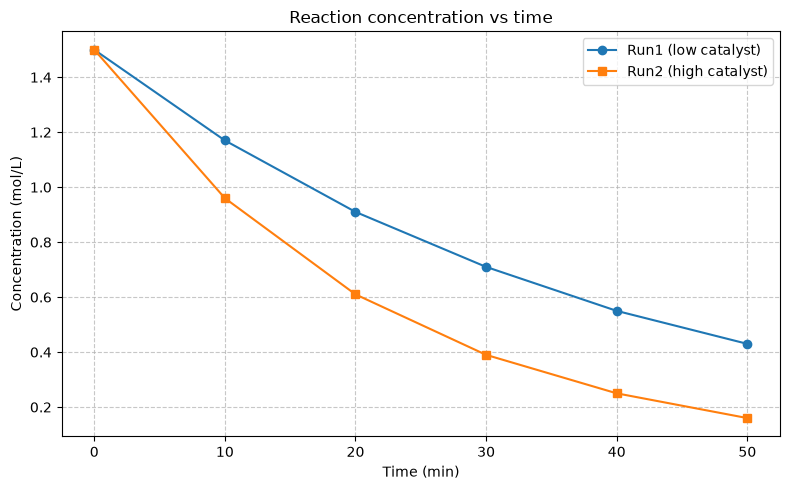

In [4]:
import matplotlib.pyplot as plt

if "kinetics_df" not in globals():
    kinetics_data = {
        "Time_min": [0, 10, 20, 30, 40, 50],
        "Run1_mol_L_low_catalyst": [1.50, 1.17, 0.91, 0.71, 0.55, 0.43],
        "Run2_mol_L_high_catalyst": [1.50, 0.96, 0.61, 0.39, 0.25, 0.16],
    }
    kinetics_df = pd.DataFrame(kinetics_data)

plt.figure(figsize=(8, 5))
plt.plot(kinetics_df["Time_min"], kinetics_df["Run1_mol_L_low_catalyst"], marker='o', label='Run1 (low catalyst)')
plt.plot(kinetics_df["Time_min"], kinetics_df["Run2_mol_L_high_catalyst"], marker='s', label='Run2 (high catalyst)')
plt.title("Reaction concentration vs time")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
(d) Ethylene gas is compressed slowly in a piston-cylinder at constant temperature: 
 Volume_L 1 2 3 4 5  Pressure_bar 5.03 2.52 1.65 1.26 1.01 
 Plot pressure vs volume as a scatter plot.
 
 
 Calculate k as the mean of P*V and draw the referance curve P=k/V on the same graph. 
Add title, labels with units and legend.

(d) Ethylene gas is compressed slowly in a piston-cylinder at constant temperature: 
 Volume_L 1 2 3 4 5  Pressure_bar 5.03 2.52 1.65 1.26 1.01 
 Plot pressure vs volume as a scatter plot.
 
 
 Calculate k as the mean of P*V and draw the referance curve P=k/V on the same graph. 
Add title, labels with units and legend.

k = 5.0220 bar·L


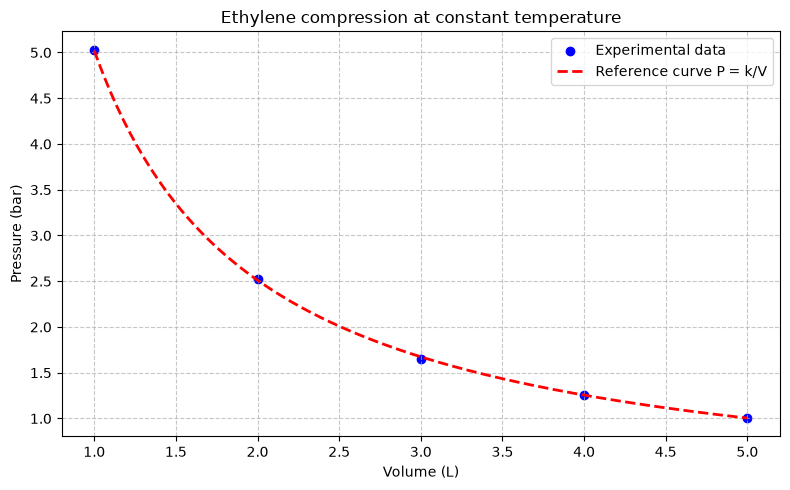

In [5]:
import numpy as np
import matplotlib.pyplot as plt

volume_L = np.array([1, 2, 3, 4, 5], dtype=float)
pressure_bar = np.array([5.03, 2.52, 1.65, 1.26, 1.01], dtype=float)

k = np.mean(pressure_bar * volume_L)
print(f"k = {k:.4f} bar·L")

volume_ref = np.linspace(1, 5, 200)
pressure_ref = k / volume_ref

plt.figure(figsize=(8, 5))
plt.scatter(volume_L, pressure_bar, color='blue', label='Experimental data')
plt.plot(volume_ref, pressure_ref, color='red', linestyle='--', linewidth=2, label='Reference curve P = k/V')
plt.title('Ethylene compression at constant temperature')
plt.xlabel('Volume (L)')
plt.ylabel('Pressure (bar)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()